# Checking the Flow Budget and Aggregating Over Types

This notebook follows the HANK income-process example of [SSJ-advanced-examples.ipynb](SSJ-advanced-examples.ipynb): it builds four household types on that income process, checks each type's sequence-space Jacobians against the household's own flow budget with `check_flow_budget`, and adds them over types with `aggregate_SSJs`.

In [1]:
# First, let's import some basic things and define a plotting function
import matplotlib.pyplot as plt
import numpy as np


# Define a simple function for plotting SSJs
def plot_SSJ(jac, S, outcome, shock, t_max=None):
    top = jac.shape[0] + 1 if t_max is None else t_max
    if type(S) is int:
        S = [S]
    for s in S:
        plt.plot(jac[:, s], "-", label="s=" + str(s))
    plt.legend()
    plt.xlabel(r"time $t$")
    plt.ylabel("rate of change of " + outcome)
    plt.title("SSJ for " + outcome + " with respect to " + shock + r" at time $s$")
    plt.tight_layout()
    plt.xlim(-1, top)
    plt.show()

In [2]:
# Import our AgentType subclass and alternative constructor
from HARK.ConsumptionSaving.ConsIndShockModel import (
    IndShockConsumerType,
    IndShockConsumerType_constructors_default,
)
from HARK.Calibration.Income.IncomeProcesses import (
    construct_HANK_lognormal_income_process_unemployment,
)

# Substitute the new constructor into the base constructor dictionary
my_constructors = IndShockConsumerType_constructors_default.copy()
my_constructors["IncShkDstn"] = construct_HANK_lognormal_income_process_unemployment

# Make a parameter dictionary with the new / updated parameters for that constructor
some_new_params = {
    "tax_rate": [0.0],
    "labor": [1.0],
    "wage": [1.0],
    "constructors": my_constructors,
}

# Make an AgentType instance with our alternative constructor
IndShkTypeWithWage = IndShockConsumerType(cycles=0, **some_new_params)

In [3]:
# Make grid specifications
assets_grid_spec = {"min": 0.0, "max": 40.0, "N": 401}
consumption_grid_spec = {"min": 0.0, "max": 5.0, "N": 151}
my_basic_grid_specs = {"kNrm": assets_grid_spec, "cNrm": consumption_grid_spec}

## Aggregating Over Types and Checking the Flow Budget

A heterogeneous-agent model usually has several types of household (education groups, discount-factor atoms, ...) whose SSJs are computed one type at a time and then added up with population weights; `aggregate_SSJs` does the adding. And whatever the model, the household block's Jacobians must obey the household's own budget. In the units `make_basic_SSJ` reports (responses per unit of the period's normalizing level), at every date $t$ and in every column $s$,

$$ dC_{t,s} + dA_{t,s} - \rho \, dA_{t-1,s} - dY_{t,s} = \mathrm{cash}_{t,s}, \qquad \rho = \frac{\mathsf{R} \, \mathsf{L}}{g}, $$

where $\mathsf{R}$ is the return factor, $\mathsf{L}$ the survival probability and $g$ the growth factor of the normalizing level that newborns inherit (`newborn_growth`, 1.0 by default): survivors bring $\mathsf{R}$ times their end-of-period assets into the next period, the dead bring nothing, and the responses are per unit of a level that grows by $g$. The right side is what the perturbation itself injects: nothing, for a perturbation that reaches the household through labor income (once $dY$ is counted) or through preferences; and for a perturbation of the interest factor, the return on the assets brought into the period, $\mathsf{L} A_{ss} / g$, on the date the perturbed return is paid. `check_flow_budget` tests this column by column and names the first date that fails. It is the acceptance test for any construction of these Jacobians, and because it appeals to no other construction as an oracle it also settles dating questions, such as which row an interest-factor perturbation dated $s$ pays on.

Below, four types share the HANK income process of the advanced examples: two groups that differ in income risk, each with two discount-factor atoms.

In [4]:
from HARK.SSJutils import aggregate_SSJs, check_flow_budget, flow_budget_residuals

# Two groups that differ in income risk, each with two discount-factor atoms
group_params = {
    "low risk": dict(PermShkStd=[0.06], TranShkStd=[0.15]),
    "high risk": dict(PermShkStd=[0.12], TranShkStd=[0.30]),
}
group_shares = {"low risk": 0.6, "high risk": 0.4}
atoms = {0.95: 0.5, 0.97: 0.5}  # discount factor : probability within the group

types = {}
for group, params in group_params.items():
    for DiscFac, prob in atoms.items():
        agent = IndShockConsumerType(
            cycles=0, DiscFac=DiscFac, **params, **some_new_params
        )
        agent.solve()
        types[(group, DiscFac)] = agent
weights = [group_shares[group] * atoms[DiscFac] for (group, DiscFac) in types]
print("population weights:", weights)

population weights: [0.3, 0.3, 0.2, 0.2]


In [5]:
# SSJs of consumption, assets and labor income for each type, with respect to the
# wage rate and the interest factor; the income Jacobian lets the budget be checked
# exactly rather than by the pattern of the cash delivered
grids = dict(
    my_basic_grid_specs, aNrm=assets_grid_spec, yNrm={"min": 0.0, "max": 5.0, "N": 151}
)
SSJs = {}
for key, agent in types.items():
    for shock in ("wage", "Rfree"):
        SSJs[key, shock] = agent.make_basic_SSJ(
            shock,
            ["cNrm", "aNrm", "yNrm"],
            grids,
            T_max=150,
            norm="G",
            offset=True,
            solved=True,
            ghost=True,
        )


# Steady state assets of each type, per unit of its level, for the interest-factor check
def steady_state_assets(agent):
    agent.initialize_sym()
    X = agent._simulator
    X.make_transition_matrices(grids, norm="G")
    X.find_steady_state()
    A_ss = X.get_long_run_average("aNrm")
    del agent._simulator
    return A_ss


A_ss = {key: steady_state_assets(agent) for key, agent in types.items()}

for key, agent in types.items():
    C, A, Y = SSJs[key, "wage"]
    worst_w = check_flow_budget(C, A, agent.Rfree, agent.LivPrb, SSJ_Y=Y)
    C, A, Y = SSJs[key, "Rfree"]
    worst_r = check_flow_budget(
        C, A, agent.Rfree, agent.LivPrb, SSJ_Y=Y, A_ss=A_ss[key], tol=1e-5
    )
    print(
        "{:9s} DiscFac {:.2f}: A_ss = {:.3f}; largest violation, wage {:.1e}, interest factor {:.1e}".format(
            key[0], key[1], A_ss[key], worst_w, worst_r
        )
    )

/tmp/claude-1000/-home-shared-github-econ-ark-HARK-dev/2392c54d-5d96-4440-a5cb-7ba9d038a7d7/scratchpad/ci-fixes/w1835/HARK/SSJutils.py:1783: NumbaPerformanceWarning: np.dot() is faster on contiguous arrays, called on (Array(float64, 2, 'A', False, aligned=True), Array(float64, 1, 'C', False, aligned=True))
  np.dot(trans_by_t[t, :, :].T, SS_dstn) - base_D[t, :]


low risk  DiscFac 0.95: A_ss = 0.409; largest violation, wage 1.0e-11, interest factor 9.6e-08
low risk  DiscFac 0.97: A_ss = 0.529; largest violation, wage 4.5e-12, interest factor 6.4e-08
high risk DiscFac 0.95: A_ss = 0.788; largest violation, wage 5.7e-12, interest factor 4.6e-08
high risk DiscFac 0.97: A_ss = 1.369; largest violation, wage 4.4e-08, interest factor 2.5e-07


Every type passes both checks: the wage Jacobians to the finite-difference step's own rounding, the interest-factor Jacobians to the discretization of the assets-to-capital transition (which is why that check is given a tolerance of $10^{-5}$; the identity itself is exact). The interest-factor check passed with the return term on the diagonal, and that is a statement about dating: with `offset=True`, the column dated $s$ is the return paid at the start of period $s$ on the assets brought into it, $\mathsf{L} A_{ss}$ per unit of the period's level. Leave the return term out and the check names the first date and column that fail:

In [6]:
key = ("low risk", 0.95)
C, A, Y = SSJs[key, "Rfree"]
agent = types[key]
try:
    check_flow_budget(C, A, agent.Rfree, agent.LivPrb, SSJ_Y=Y)
except ValueError as e:
    print(e)
res = flow_budget_residuals(C, A, agent.Rfree, agent.LivPrb, SSJ_Y=Y)
print(
    "residual on the diagonal at the first five dates:", np.round(np.diag(res)[:5], 4)
)
print("LivPrb * A_ss:", round(agent.LivPrb[0] * A_ss[key], 4))

The flow-budget identity fails: at date t=0 of the perturbation dated s=0 the residual is 4.0048e-01 where 0.0000e+00 was expected (6.22e-01 of the Jacobians' scale; tolerance 1.0e-06).
residual on the diagonal at the first five dates: [0.4005 0.4005 0.4005 0.4005 0.4005]
LivPrb * A_ss: 0.4005


With the identity holding type by type, aggregation is a weighted sum. The weights are each type's share of the population's normalizing level. Here every type's newborns start at the same level and share the same growth and mortality, so their mean levels coincide whatever their preferences and the population weights are the right ones; types with different growth or mortality have different mean levels, and the weight is then the population share times the type's mean level relative to the population's. The identity is linear, so the aggregate obeys it with the same $\rho$ and the aggregated $A_{ss}$.

aggregate, wage: largest violation 8.9e-09
aggregate, interest factor: largest violation 7.6e-08


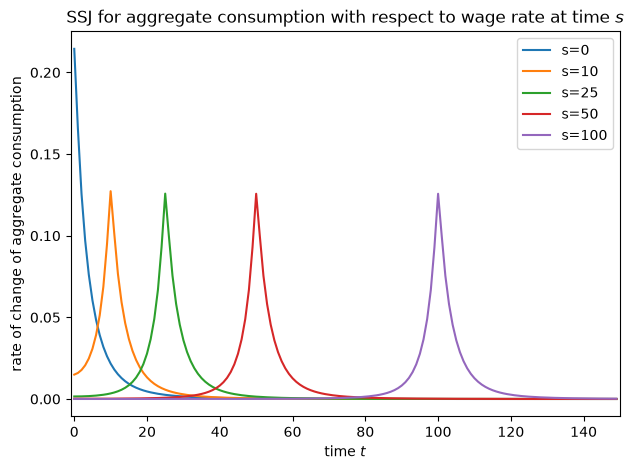

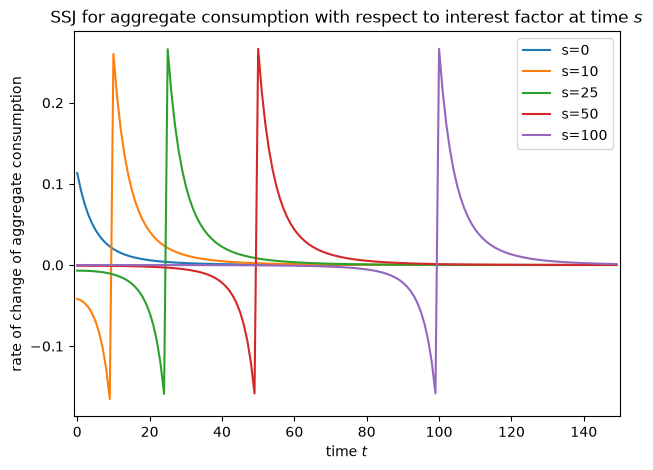

In [7]:
aggregate = {
    shock: aggregate_SSJs([SSJs[key, shock] for key in types], weights)
    for shock in ("wage", "Rfree")
}
A_ss_aggregate = sum(w * A_ss[key] for key, w in zip(types, weights))
some_agent = types[
    ("low risk", 0.95)
]  # the return factor and survival probability are common to all types

C, A, Y = aggregate["wage"]
print(
    "aggregate, wage: largest violation {:.1e}".format(
        check_flow_budget(C, A, some_agent.Rfree, some_agent.LivPrb, SSJ_Y=Y)
    )
)
C, A, Y = aggregate["Rfree"]
print(
    "aggregate, interest factor: largest violation {:.1e}".format(
        check_flow_budget(
            C,
            A,
            some_agent.Rfree,
            some_agent.LivPrb,
            SSJ_Y=Y,
            A_ss=A_ss_aggregate,
            tol=1e-5,
        )
    )
)
plot_SSJ(
    aggregate["wage"][0],
    [0, 10, 25, 50, 100],
    "aggregate consumption",
    "wage rate",
    t_max=150,
)
plot_SSJ(
    aggregate["Rfree"][0],
    [0, 10, 25, 50, 100],
    "aggregate consumption",
    "interest factor",
    t_max=150,
)